
# Week 3 Task: Exploratory Data Analysis and Visualization

## Project: Smart Supply Chain Analytics

**Internship:** Data Analytics Strategist Internship  
**Organization:** InAmigos Foundation  
**Dataset:** DataCo Smart Supply Chain for Big Data Analysis  
**Dataset Source:** https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis

### Objective
To explore the supply-chain dataset, summarize important variables, identify missing values and potential data-quality issues, and visualize sales, product categories, profitability and shipping performance.

### Tools
- Python
- pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)


## 2. Load the dataset

In [3]:

file_path = Path("DataCoSupplyChainDataset.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "CSV not found. Place DataCoSupplyChainDataset.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(file_path, encoding="latin1", low_memory=False)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully.
Number of rows: 180519
Number of columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


### Dataset structure

In [4]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nData types:")
display(df.dtypes.astype(str).rename("Data Type").to_frame())


Dataset shape: (180519, 53)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price',

,Data Type
Type,object
Days for shipping (real),int64
Days for shipment (scheduled),int64
Benefit per order,float64
Sales per customer,float64
Delivery Status,object
Late_delivery_risk,int64
Category Id,int64
Category Name,object
Customer City,object


###Descriptive statistics

In [5]:

print("Numerical Summary")
display(df.describe().T)

print("Categorical and Overall Summary")
display(df.describe(include="all").T)

numeric_columns = df.select_dtypes(include=np.number).columns

numerical_summary = df[numeric_columns].describe().T
numerical_summary["missing_count"] = df[numeric_columns].isna().sum()
numerical_summary["missing_percentage"] = (
    df[numeric_columns].isna().mean() * 100
).round(2)

display(numerical_summary)


Numerical Summary


,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


Categorical and Overall Summary


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,180519,4,DEBIT,69295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days for shipping (real),180519.0,NaN,NaN,NaN,3.497654,1.623722,0.0,2.0,3.0,5.0,6.0
Days for shipment (scheduled),180519.0,NaN,NaN,NaN,2.931847,1.374449,0.0,2.0,4.0,4.0,4.0
Benefit per order,180519.0,NaN,NaN,NaN,21.974989,104.433526,-4274.97998,7.0,31.52,64.800003,911.799988
Sales per customer,180519.0,NaN,NaN,NaN,183.107609,120.04367,7.49,104.379997,163.990005,247.399994,1939.98999
Delivery Status,180519,4,Late delivery,98977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Late_delivery_risk,180519.0,NaN,NaN,NaN,0.548291,0.497664,0.0,0.0,1.0,1.0,1.0
Category Id,180519.0,NaN,NaN,NaN,31.851451,15.640064,2.0,18.0,29.0,45.0,76.0
Category Name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer City,180519,563,Caguas,66770,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,mean,std,min,25%,50%,75%,max,missing_count,missing_percentage
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000,0,0.00
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000,0,0.00
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988,0,0.00
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990,0,0.00
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000,0,0.00
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000,0,0.00
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000,0,0.00
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000,3,0.00
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000,0,0.00
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933,0,0.00


### Missing-value analysis

,Missing Count,Missing Percentage
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


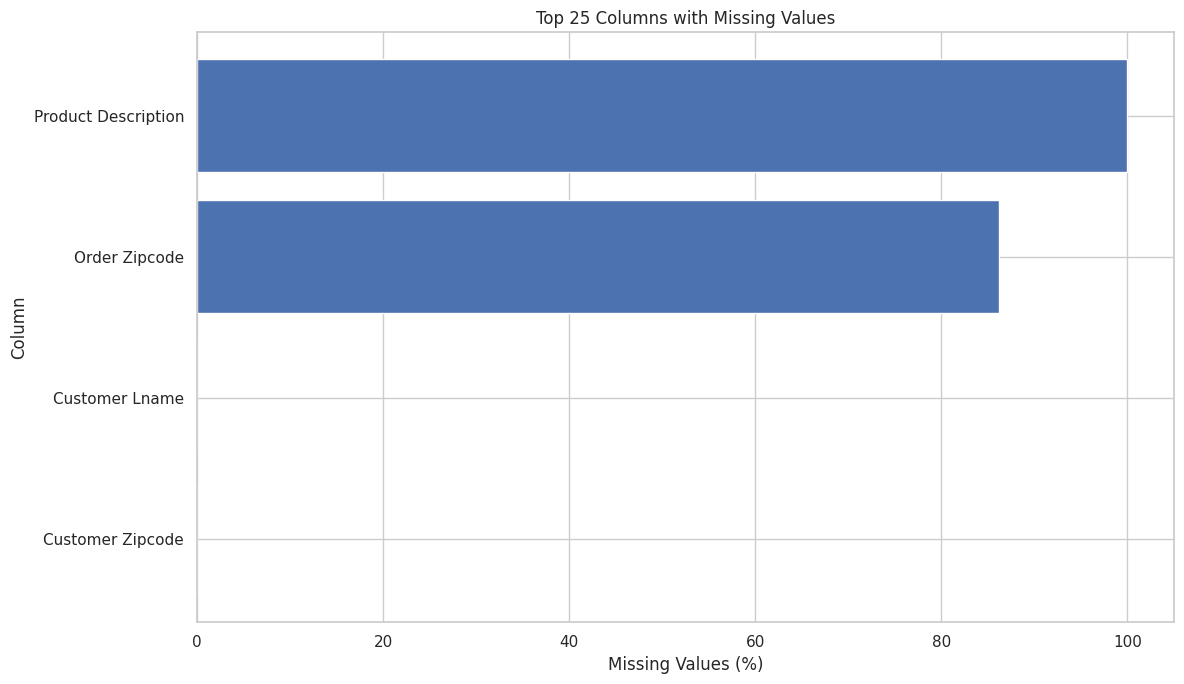

In [6]:

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_summary[missing_summary["Missing Count"] > 0])

missing_to_plot = missing_summary[
    missing_summary["Missing Count"] > 0
].head(25).sort_values("Missing Percentage")

if not missing_to_plot.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        missing_to_plot.index,
        missing_to_plot["Missing Percentage"]
    )
    plt.title("Top 25 Columns with Missing Values")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


### Duplicate-row check

In [7]:

exact_duplicates = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)
print("Percentage of exact duplicate rows:",
      round(exact_duplicates / len(df) * 100, 2), "%")

print("\nRepeated Order Id values are checked separately.")

if "Order Id" in df.columns:
    print("Rows with repeated Order Id:",
          df["Order Id"].duplicated().sum())
    print("Unique Order Id count:",
          df["Order Id"].nunique())
else:
    print("Order Id column was not found. Check the column names.")


Exact duplicate rows: 0
Percentage of exact duplicate rows: 0.0 %

Repeated Order Id values are checked separately.
Rows with repeated Order Id: 114767
Unique Order Id count: 65752


### Numerical columns and outlier review

Numerical columns: ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Price', 'Product Status']


,count,mean,std,min,25%,50%,75%,max
Sales,180519.0,203.772096,132.273077,9.99000,119.980003,199.919998,299.950012,1999.989990
Order Item Quantity,180519.0,2.127638,1.453451,1.00000,1.000000,1.000000,3.000000,5.000000
Order Item Discount,180519.0,20.664741,21.800901,0.00000,5.400000,14.000000,29.990000,500.000000
Order Profit Per Order,180519.0,21.974989,104.433526,-4274.97998,7.000000,31.520000,64.800003,911.799988
Days for shipping (real),180519.0,3.497654,1.623722,0.00000,2.000000,3.000000,5.000000,6.000000


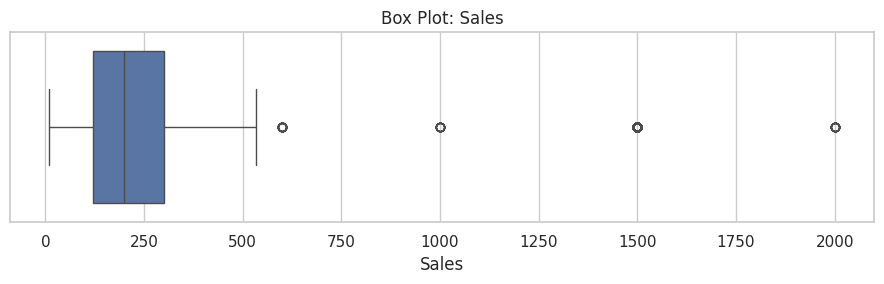

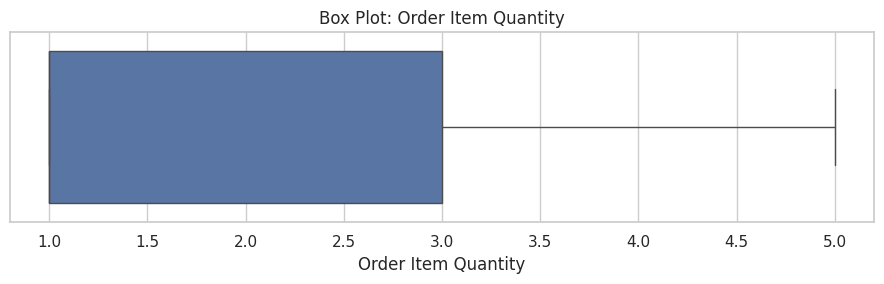

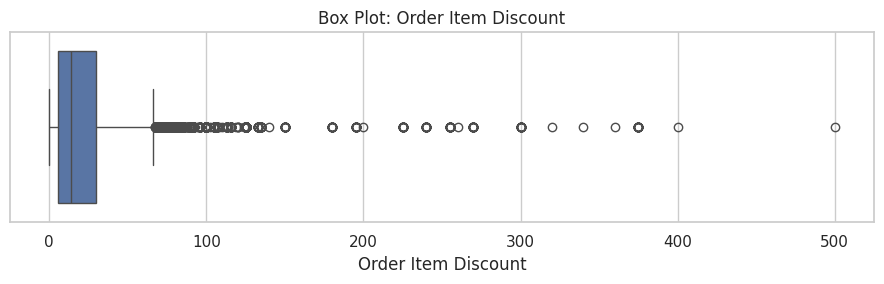

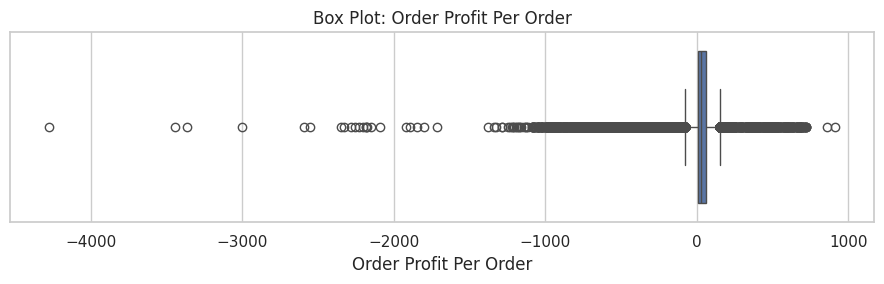

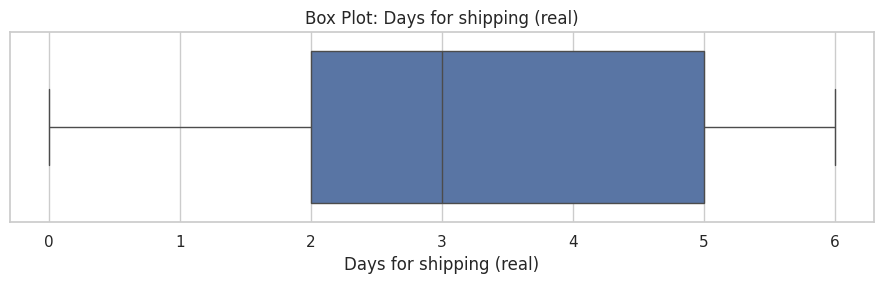

In [8]:

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns:", numeric_columns)

selected_numeric = [
    col for col in [
        "Sales",
        "Order Item Quantity",
        "Order Item Discount",
        "Order Profit Per Order",
        "Days for shipping (real)"
    ]
    if col in df.columns
]

if selected_numeric:
    display(df[selected_numeric].describe().T)

    for col in selected_numeric:
        plt.figure(figsize=(9, 3))
        sns.boxplot(x=df[col].dropna())
        plt.title(f"Box Plot: {col}")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()
else:
    print("No selected numerical columns were found.")


### Monthly sales trend

,Total Sales
order date (DateOrders),
2015-01-01,1.051590e+06
2015-02-01,9.270099e+05
2015-03-01,1.051254e+06
2015-04-01,1.014463e+06
2015-05-01,1.050478e+06
2015-06-01,1.024006e+06
2015-07-01,1.038081e+06
2015-08-01,1.029495e+06
2015-09-01,1.018339e+06


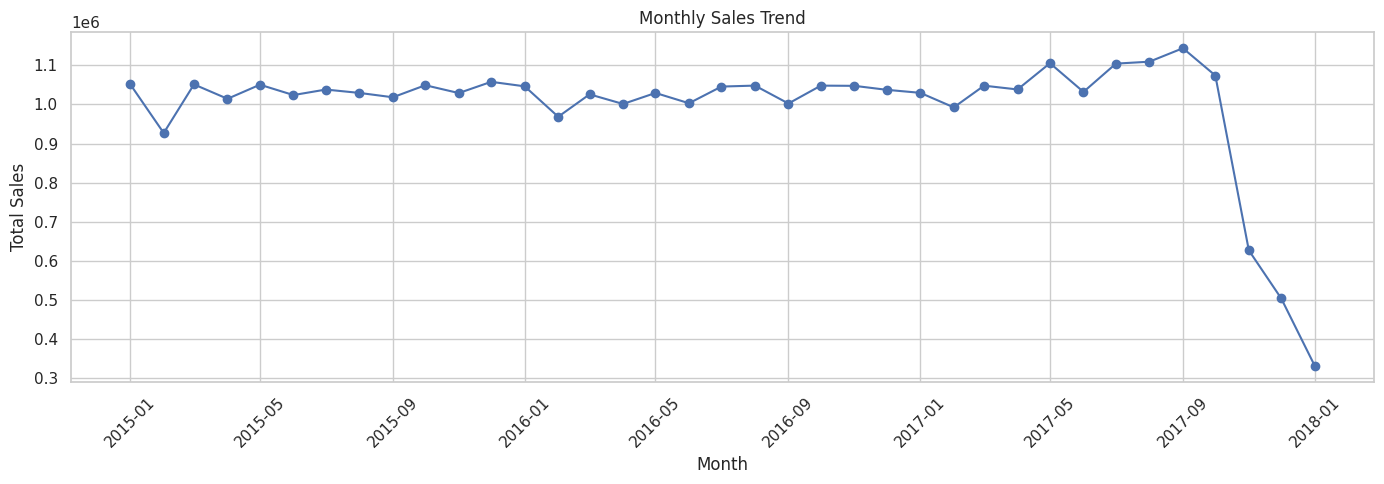

In [10]:
order_date_col = 'order date (DateOrders)'

if order_date_col in df.columns and "Sales" in df.columns:
    # Ensure the column is converted to datetime for resampling
    df[order_date_col] = pd.to_datetime(df[order_date_col])

    monthly_sales = (
        df.dropna(subset=[order_date_col])
        .set_index(order_date_col)["Sales"]
        .resample("MS")
        .sum()
    )

    display(monthly_sales.rename("Total Sales").to_frame())

    plt.figure(figsize=(14, 5))
    plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Order date or Sales column is missing.")

### Sales by product category

,Total Sales
Category Name,
Fishing,6.929654e+06
Cleats,4.431943e+06
Camping & Hiking,4.118426e+06
Cardio Equipment,3.694843e+06
Women's Apparel,3.147800e+06
Water Sports,3.113845e+06
Men's Footwear,2.891758e+06
Indoor/Outdoor Games,2.888994e+06
Shop By Sport,1.309522e+06


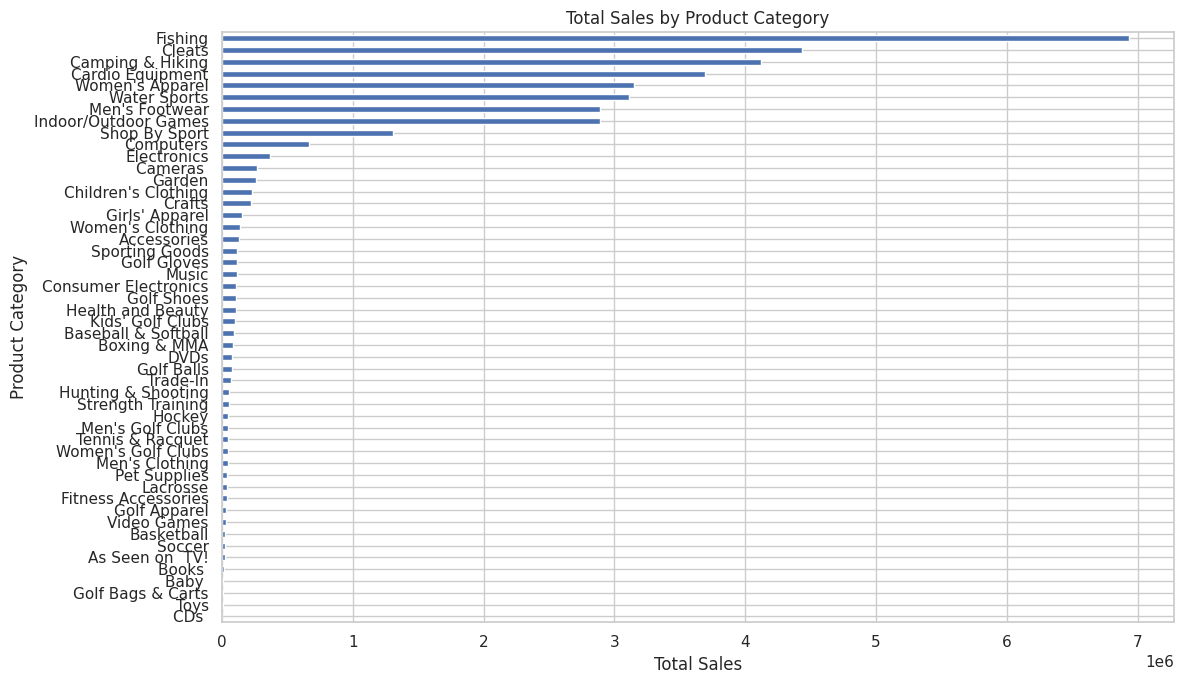

In [11]:

if "Category Name" in df.columns and "Sales" in df.columns:
    category_sales = (
        df.groupby("Category Name")["Sales"]
        .sum()
        .sort_values(ascending=False)
    )

    display(category_sales.rename("Total Sales").to_frame())

    plt.figure(figsize=(12, 7))
    category_sales.sort_values().plot(kind="barh")
    plt.title("Total Sales by Product Category")
    plt.xlabel("Total Sales")
    plt.ylabel("Product Category")
    plt.tight_layout()
    plt.show()
else:
    print("Category Name or Sales column is missing.")


### Sales by market or region

,Total Sales
Market,
Europe,1.087240e+07
LATAM,1.027761e+07
Pacific Asia,8.273744e+06
USCA,5.066529e+06
Africa,2.294453e+06


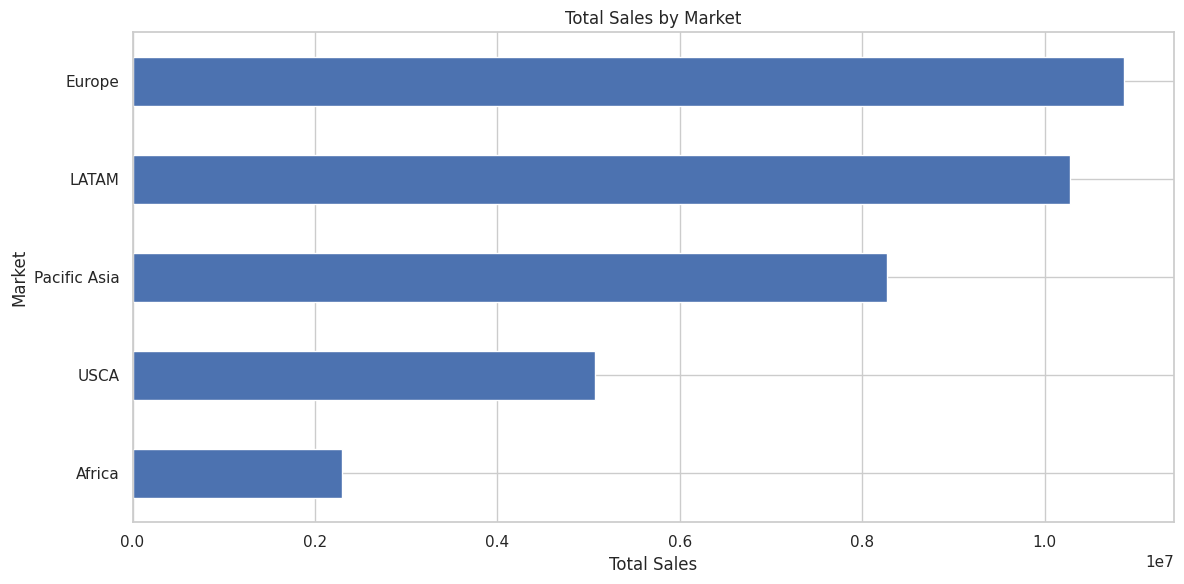

In [12]:

group_column = (
    "Market" if "Market" in df.columns
    else "Order Region" if "Order Region" in df.columns
    else None
)

if group_column and "Sales" in df.columns:
    geographic_sales = (
        df.groupby(group_column)["Sales"]
        .sum()
        .sort_values(ascending=False)
    )

    display(geographic_sales.rename("Total Sales").to_frame())

    plt.figure(figsize=(12, 6))
    geographic_sales.sort_values().plot(kind="barh")
    plt.title(f"Total Sales by {group_column}")
    plt.xlabel("Total Sales")
    plt.ylabel(group_column)
    plt.tight_layout()
    plt.show()
else:
    print("No suitable geographical column or Sales column found.")


### Sales distribution

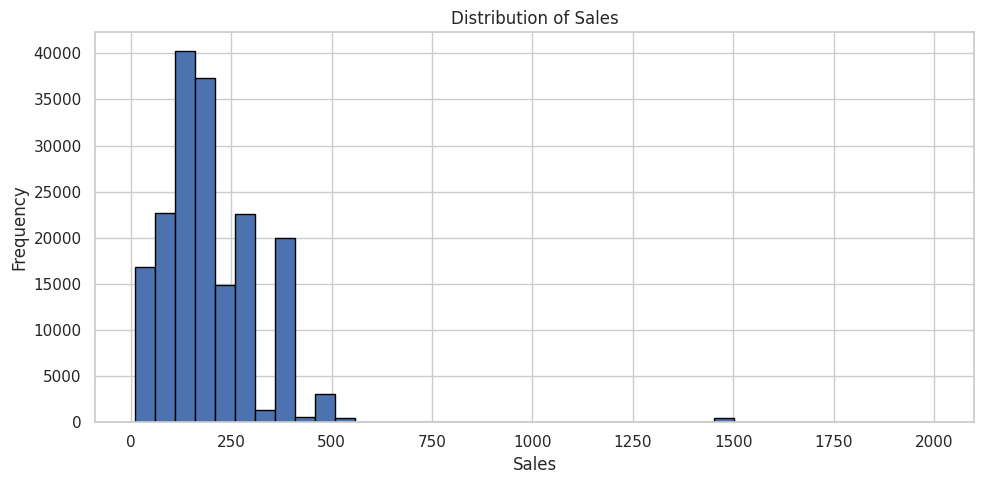

Sales skewness: 2.884
Sales median: 199.9199982
Sales mean: 203.77209608617287


In [13]:

if "Sales" in df.columns:
    sales_values = df["Sales"].dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(sales_values, bins=40, edgecolor="black")
    plt.title("Distribution of Sales")
    plt.xlabel("Sales")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    print("Sales skewness:", round(sales_values.skew(), 3))
    print("Sales median:", sales_values.median())
    print("Sales mean:", sales_values.mean())
else:
    print("Sales column is missing.")


In [14]:
### Shipping duration by shipping mode

### Actual versus scheduled shipping time

Mean actual shipping days: 3.5
Mean scheduled shipping days: 2.93
Records where actual days exceed scheduled days: 103400


,Delay Difference
count,180519.000000
mean,0.565807
std,1.490966
min,-2.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,4.000000


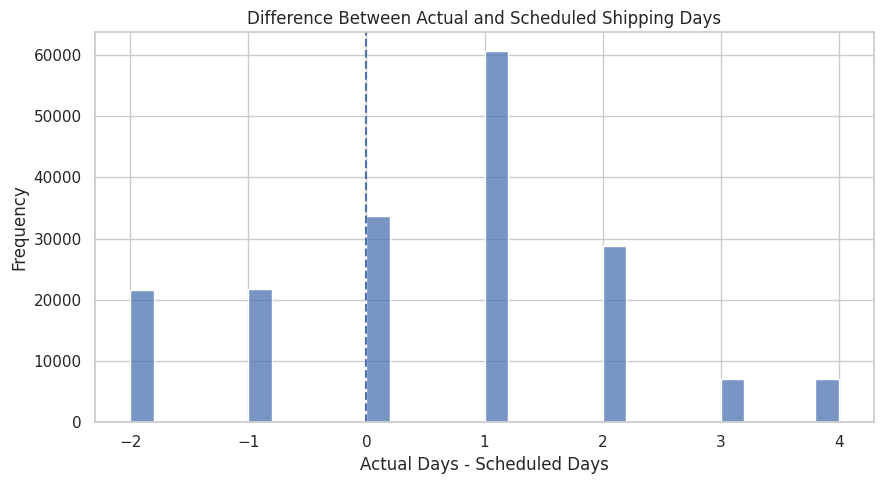

In [15]:

actual_col = "Days for shipping (real)"
scheduled_col = "Days for shipment (scheduled)"

if actual_col in df.columns and scheduled_col in df.columns:
    shipping_comparison = df[
        [actual_col, scheduled_col]
    ].dropna().copy()

    shipping_comparison["Delay Difference"] = (
        shipping_comparison[actual_col]
        - shipping_comparison[scheduled_col]
    )

    print("Mean actual shipping days:",
          round(shipping_comparison[actual_col].mean(), 2))
    print("Mean scheduled shipping days:",
          round(shipping_comparison[scheduled_col].mean(), 2))
    print("Records where actual days exceed scheduled days:",
          (shipping_comparison["Delay Difference"] > 0).sum())

    display(
        shipping_comparison["Delay Difference"]
        .describe()
        .to_frame("Delay Difference")
    )

    plt.figure(figsize=(9, 5))
    sns.histplot(
        shipping_comparison["Delay Difference"],
        bins=30
    )
    plt.axvline(0, linestyle="--")
    plt.title("Difference Between Actual and Scheduled Shipping Days")
    plt.xlabel("Actual Days - Scheduled Days")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("Actual or scheduled shipping-time column is missing.")


### Delivery status by shipping mode

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping Mode,,,,
First Class,0,26513,1301,0
Same Day,0,4454,444,4839
Second Class,0,26987,1410,6819
Standard Class,41592,41023,4599,20538


Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping Mode,,,,
First Class,0.0,95.32,4.68,0.00
Same Day,0.0,45.74,4.56,49.70
Second Class,0.0,76.63,4.00,19.36
Standard Class,38.6,38.07,4.27,19.06


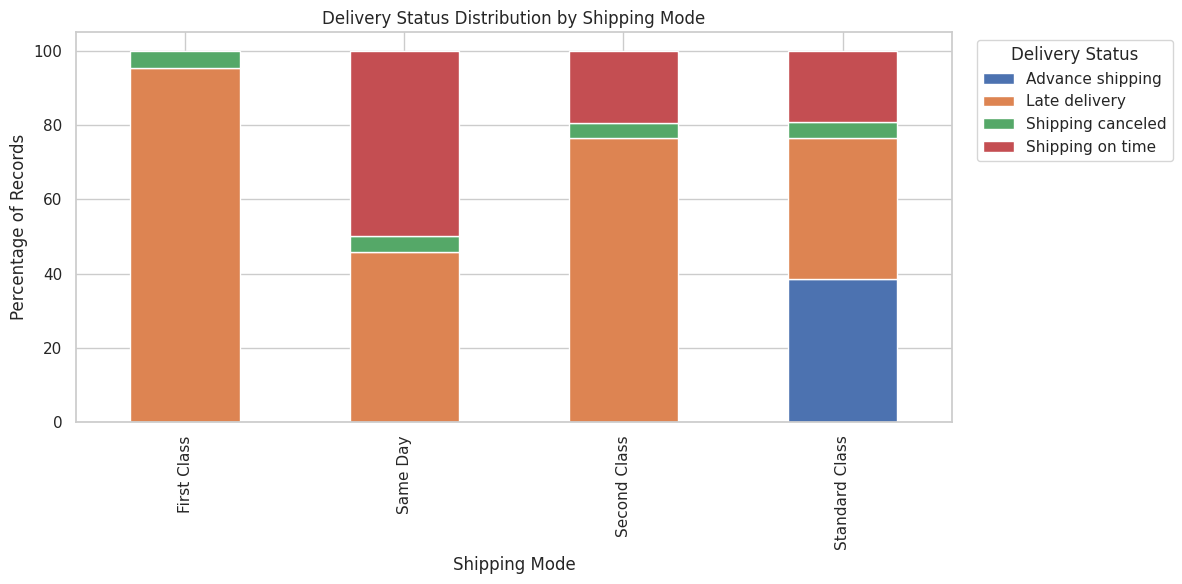

In [17]:
shipping_mode_col = "Shipping Mode"
delivery_col = "Delivery Status"

if shipping_mode_col in df.columns and delivery_col in df.columns:
    delivery_counts = pd.crosstab(
        df[shipping_mode_col],
        df[delivery_col]
    )

    display(delivery_counts)

    delivery_percentages = pd.crosstab(
        df[shipping_mode_col],
        df[delivery_col],
        normalize="index"
    ) * 100

    display(delivery_percentages.round(2))

    delivery_percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Delivery Status Distribution by Shipping Mode")
    plt.xlabel("Shipping Mode")
    plt.ylabel("Percentage of Records")
    plt.legend(title="Delivery Status", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()
else:
    print("Shipping Mode or Delivery Status column is missing.")

### Correlation heatmap

,Sales,Order Item Discount,Order Item Quantity,Order Profit Per Order,Days for shipping (real),Days for shipment (scheduled)
Sales,1.000,0.617,0.106,0.132,0.002,0.006
Order Item Discount,0.617,1.000,0.065,0.065,0.002,0.003
Order Item Quantity,0.106,0.065,1.000,0.016,-0.001,-0.003
Order Profit Per Order,0.132,0.065,0.016,1.000,-0.005,-0.000
Days for shipping (real),0.002,0.002,-0.001,-0.005,1.000,0.516
Days for shipment (scheduled),0.006,0.003,-0.003,-0.000,0.516,1.000


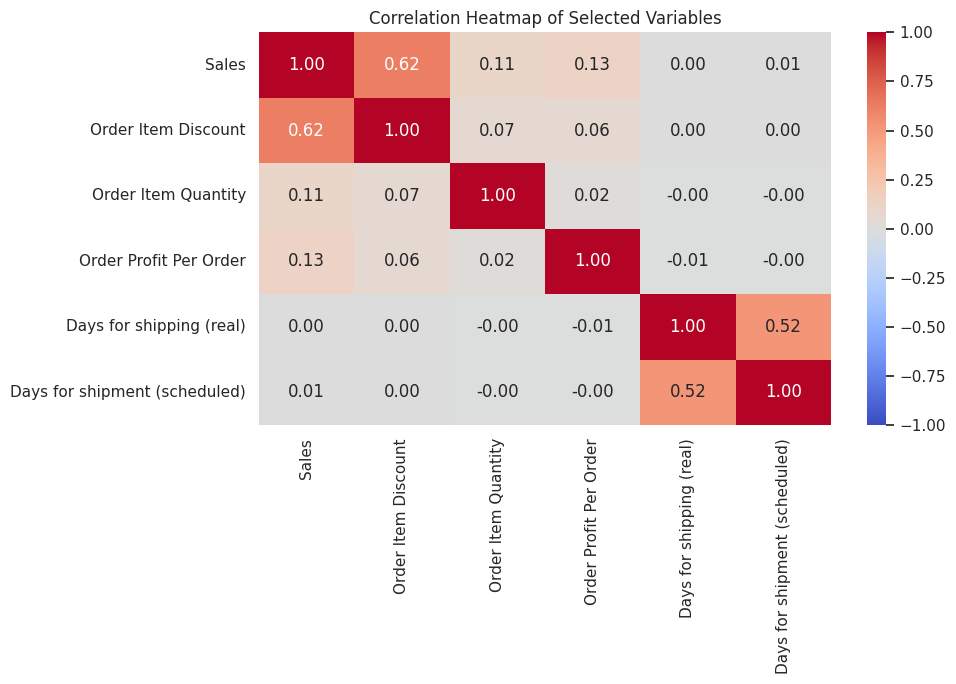

In [18]:

correlation_candidates = [
    "Sales",
    "Order Item Discount",
    "Order Item Quantity",
    "Order Profit Per Order",
    "Days for shipping (real)",
    "Days for shipment (scheduled)"
]

correlation_columns = [
    col for col in correlation_candidates
    if col in df.columns
]

if len(correlation_columns) >= 2:
    correlation_matrix = df[correlation_columns].corr()

    display(correlation_matrix.round(3))

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1
    )
    plt.title("Correlation Heatmap of Selected Variables")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns were found.")


### Discount versus profit

,count,mean,std,min,25%,50%,75%,max
Order Item Discount,180519.0,20.664741,21.800901,0.00000,5.4,14.00,29.990000,500.000000
Order Profit Per Order,180519.0,21.974989,104.433526,-4274.97998,7.0,31.52,64.800003,911.799988


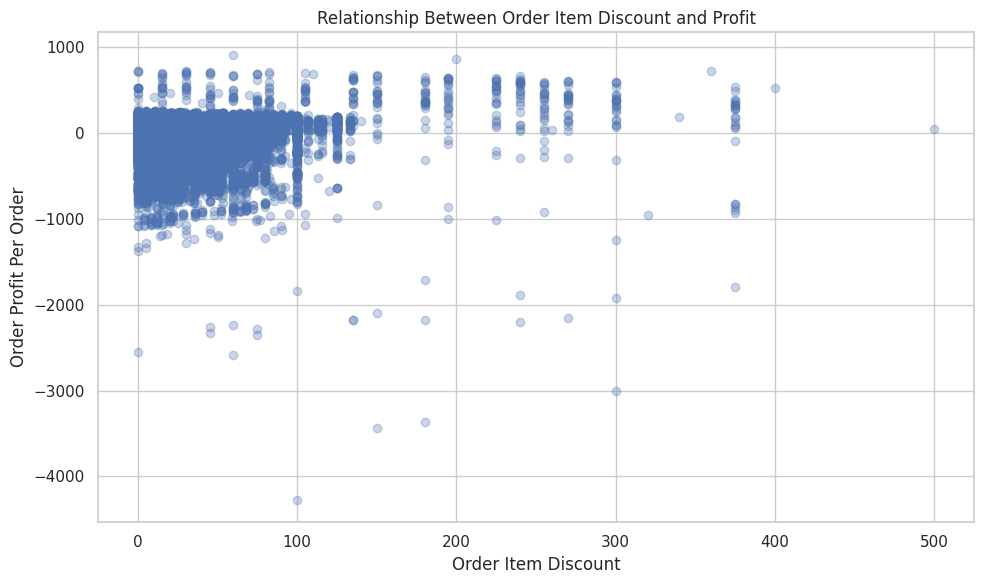

Correlation: 0.065


In [19]:

discount_col = "Order Item Discount"
profit_col = "Order Profit Per Order"

if discount_col in df.columns and profit_col in df.columns:
    scatter_data = df[[discount_col, profit_col]].dropna()

    display(scatter_data.describe().T)

    plt.figure(figsize=(10, 6))
    plt.scatter(
        scatter_data[discount_col],
        scatter_data[profit_col],
        alpha=0.3
    )
    plt.title("Relationship Between Order Item Discount and Profit")
    plt.xlabel("Order Item Discount")
    plt.ylabel("Order Profit Per Order")
    plt.tight_layout()
    plt.show()

    print(
        "Correlation:",
        round(scatter_data[discount_col].corr(
            scatter_data[profit_col]
        ), 3)
    )
else:
    print("Discount or profit column is missing.")


### Sales by customer segment

,Total Sales,Average Sales per Row,Order-Item Record Count
Customer Segment,,,
Consumer,1.909579e+07,204.224313,93504
Corporate,1.116841e+07,203.843962,54789
Home Office,6.520538e+06,202.337802,32226


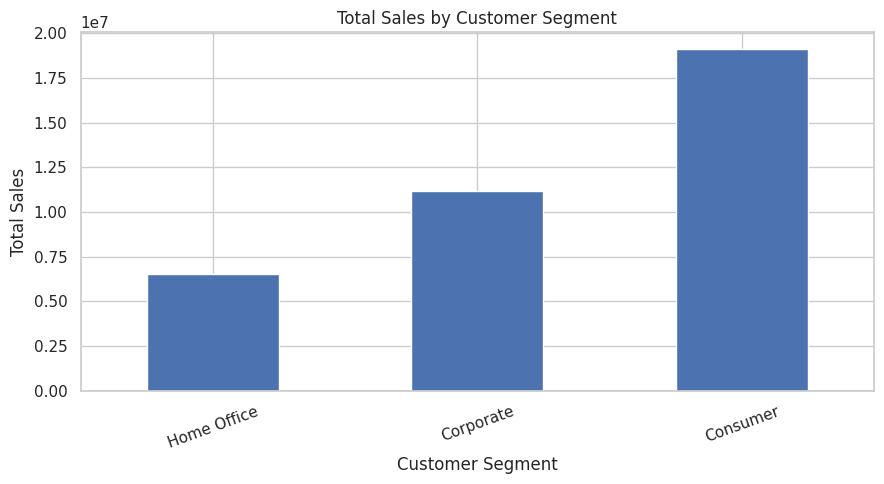

In [20]:

segment_col = "Customer Segment"

if segment_col in df.columns and "Sales" in df.columns:
    segment_sales = (
        df.groupby(segment_col)["Sales"]
        .agg(["sum", "mean", "count"])
        .sort_values("sum", ascending=False)
    )

    segment_sales.columns = [
        "Total Sales",
        "Average Sales per Row",
        "Order-Item Record Count"
    ]

    display(segment_sales)

    segment_sales["Total Sales"].sort_values().plot(
        kind="bar",
        figsize=(9, 5)
    )
    plt.title("Total Sales by Customer Segment")
    plt.xlabel("Customer Segment")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
else:
    print("Customer Segment or Sales column is missing.")


### Order status summary

,Record Count,Percentage
Order Status,,
COMPLETE,59491,32.96
PENDING_PAYMENT,39832,22.07
PROCESSING,21902,12.13
PENDING,20227,11.20
CLOSED,19616,10.87
ON_HOLD,9804,5.43
SUSPECTED_FRAUD,4062,2.25
CANCELED,3692,2.05
PAYMENT_REVIEW,1893,1.05


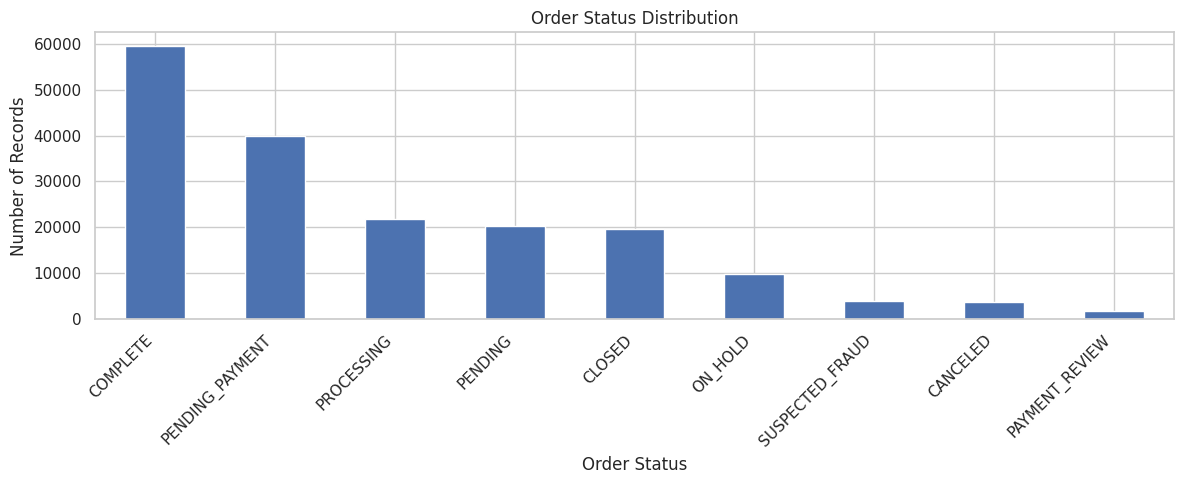

In [21]:

status_col = "Order Status"

if status_col in df.columns:
    status_summary = df[status_col].value_counts(
        dropna=False
    ).to_frame("Record Count")

    status_summary["Percentage"] = (
        status_summary["Record Count"] / len(df) * 100
    ).round(2)

    display(status_summary)

    df[status_col].value_counts().plot(
        kind="bar",
        figsize=(12, 5)
    )
    plt.title("Order Status Distribution")
    plt.xlabel("Order Status")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Order Status column is missing.")


### Create a summary of findings

In [22]:

print("EDA SUMMARY")
print("=" * 50)

print(f"Dataset rows: {df.shape[0]:,}")
print(f"Dataset columns: {df.shape[1]:,}")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

total_missing = int(df.isna().sum().sum())
total_cells = df.shape[0] * df.shape[1]

print(f"Missing cells: {total_missing:,}")
print(f"Missing cells (%): {total_missing / total_cells * 100:.2f}%")

if "Sales" in df.columns:
    print(f"Total recorded sales: {df['Sales'].sum():,.2f}")
    print(f"Average sales per row: {df['Sales'].mean():,.2f}")
    print(f"Median sales per row: {df['Sales'].median():,.2f}")

if "Category Name" in df.columns and "Sales" in df.columns:
    top_category = df.groupby("Category Name")["Sales"].sum().idxmax()
    print(f"Category with highest recorded sales: {top_category}")

if group_column and "Sales" in df.columns:
    top_group = df.groupby(group_column)["Sales"].sum().idxmax()
    print(f"{group_column} with highest recorded sales: {top_group}")

if "Delivery Status" in df.columns:
    print("\nDelivery status counts:")
    print(df["Delivery Status"].value_counts(dropna=False))

print("\nUse the actual tables and charts above to interpret results.")
print("Do not treat correlations or grouped differences as proof of causation.")


EDA SUMMARY
Dataset rows: 180,519
Dataset columns: 53
Exact duplicate rows: 0
Missing cells: 336,209
Missing cells (%): 3.51%
Total recorded sales: 36,784,735.01
Average sales per row: 203.77
Median sales per row: 199.92
Category with highest recorded sales: Fishing
Market with highest recorded sales: Europe

Delivery status counts:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Use the actual tables and charts above to interpret results.
Do not treat correlations or grouped differences as proof of causation.


### Export analysis tables

In [24]:
output_dir = Path("eda_outputs")
output_dir.mkdir(exist_ok=True)

# Define missing columns
shipping_days_col = "Days for shipping (real)"

missing_summary.to_csv(
    output_dir / "missing_value_summary.csv"
)

df.describe(include="all").T.to_csv(
    output_dir / "descriptive_statistics.csv"
)

if "Category Name" in df.columns and "Sales" in df.columns:
    category_sales.to_csv(
        output_dir / "sales_by_category.csv"
    )

if order_date_col in df.columns and "Sales" in df.columns:
    monthly_sales.to_csv(
        output_dir / "monthly_sales.csv"
    )

if shipping_mode_col in df.columns and shipping_days_col in df.columns:
    df.groupby(shipping_mode_col)[shipping_days_col].agg(
        ["count", "mean", "median", "min", "max"]
    ).to_csv(
        output_dir / "shipping_duration_summary.csv"
    )

print("Analysis tables saved to:", output_dir.resolve())

Analysis tables saved to: /content/eda_outputs


### Final conclusion


## Conclusion

Exploratory Data Analysis was planned and performed to understand the structure, quality and business patterns of the DataCo Smart Supply Chain dataset.

The analysis includes descriptive statistics, missing-value checks, duplicate-row checks, sales trends, product-category comparisons, geographical summaries, shipping performance, delivery-status distributions and relationships between selected numerical variables.

The charts and summary tables should be interpreted using the actual calculated results. Missing values, repeated order identifiers and possible outliers must be investigated before making business decisions.

Correlation does not prove causation, and the dataset may not contain all the inventory and supplier information required for complete inventory optimization or supplier-performance analysis.

The results can support future dashboard development and help identify areas for further investigation.
